# Assignment 1 – Evolutionary Algorithms
## Colouring the map of Europe with a Genetic Algorithm

**Course:** ZM002 Artificial Intelligence – Zuyd University of Applied Sciences
**Student:** Caio Alcantara
**Video:** https://drive.google.com/file/d/1koEEVWC0W1EUzXo33uEpmfz98VOeafjn/view?usp=sharing

## 1. Introduction

### The problem

The task of this assignment is to colour the map of Europe with **four colours** (red, light green,
dark blue and yellow) so that **no two countries that share a border have the same colour**. This is
the classic *map colouring problem*, a special case of the *graph colouring problem*: every country
is a vertex, every border is an edge, and adjacent vertices must get different colours. By the four
colour theorem a solution with four colours always exists for a map, but finding one is not trivial:
with 51 countries and 4 colours there are $4^{51}$ possible colourings, far too many to try one by
one.

### The approach

Instead of constructing the solution step by step, this notebook uses a **genetic algorithm (GA)**:
a population of random colourings is improved over many generations by selecting the better ones,
recombining them and applying small random changes, until a colouring without conflicts appears.
A GA does not need to know *how* to solve the problem, it only needs a way to *compare* candidate
solutions, which here is simply counting the borders in conflict.

The research question of the assignment is therefore not only *can* a GA colour the map, but *which*
sub-algorithms and hyperparameters make it do so reliably and quickly. For every step of the GA
(parent selection, crossover, mutation, survivor selection) several options were researched in the
literature, one was chosen and implemented as the default, and the alternatives were implemented
too, so that they can be compared experimentally.

### Structure of this notebook

The notebook is the complete deliverable: research report, implementation and evaluation.

| Section | Content |
|---|---|
| 2. Theoretical background | Literature review of the representation, fitness function and the four sub-algorithms, with pros and cons and the choices made |
| 3. The map of Europe | The countries, the hand-written list of borders and the code that colours the SVG map |
| 4. Implementation | The genetic algorithm, one commented function per step, and a single animated run |
| 5. Evaluation | Experiments comparing the sub-algorithms and hyperparameters over many runs, with tables, plots and interpretation |
| 6. Conclusion | The best combination and why |

All code was written for this assignment; the
overall structure follows the course notebook on genetic algorithms and the paper of Hindi &
Yampolskiy (2012), which are both cited in the references.

## 2. Theoretical background

A Genetic Algorithm (GA) is a search method inspired by natural evolution. Instead of building one
solution step by step, a GA keeps a **population** of candidate solutions and improves it over many
**generations** using selection, recombination and mutation (Eiben & Smith, 2015). The general loop is
always the same (see also the course notebook `ai_dc3_genetic_algorithm`):

1. **Initialise** a population of random candidates
2. **Evaluate** each candidate with a fitness function
3. **Repeat** until a stop condition is met:
   1. **Select parents**
   2. **Recombine** parents into children (crossover)
   3. **Mutate** the children
   4. **Evaluate** the children
   5. **Select survivors** for the next generation

To apply a GA to a concrete problem we have to decide on a **representation**, a **fitness function**
and the four **sub-algorithms** (parent selection, crossover, mutation, survivor selection). This
section reviews the options for each and explains the choices made for this assignment.

The main reference for this work is Hindi & Yampolskiy (2012), who apply a simple GA to the Graph
Coloring Problem (GCP) with a fixed number of colours. Colouring the map of Europe is exactly a GCP:
every country is a vertex and every border is an edge, and two vertices connected by an edge may
not have the same colour. Hindi & Yampolskiy use a second post-processing algorithm ("Wisdom of
Artificial Crowds") when the GA fails; that part is **not** used here. If the GA does not find a
solution within the maximum number of generations, the run simply counts as a failure.

### 2.1 Genetic representation

The representation (or *encoding*) defines what a chromosome looks like. Hindi & Yampolskiy (2012)
represent a colouring as **an array with one cell per vertex, where each cell holds a number from
`0` to `number_of_colours - 1`**. The borders are stored separately as an adjacency structure.

For this assignment the same representation is used: a Python list with one integer (0 to 3) per
country, in a fixed order. The four values map to the four colours of the assignment (red, light
green, dark blue, yellow).

| Option | Pros | Cons |
|---|---|---|
| **Integer array** (one gene per country) | Direct: every list is a valid colouring; easy to read, mutate and cross over; used by Hindi & Yampolskiy | Colours are just labels, so the same colouring can be written in several ways (e.g. swapping red and blue) |
| Binary string (2 bits per country) | Classic GA representation (Goldberg-style) | Longer chromosome, crossover can cut inside a gene, no real advantage with only 4 colours |

The integer array was chosen because it is the simplest encoding that guarantees every chromosome
is a valid candidate (there is no way to produce an "illegal" individual), and it matches the
reference paper.

### 2.2 Fitness function

The fitness expresses how good a candidate is. Hindi & Yampolskiy (2012) define a **bad edge** as an
edge whose two vertices have the same colour, and use **the number of bad edges as the fitness
score**. A chromosome with fitness `0` is a valid colouring. This is therefore a fitness that must be
**minimised**, and the GA stops as soon as a chromosome with fitness `0` is found or when the maximum
number of generations is reached.

The same fitness is used here: the number of borders where both countries have the same colour.
It is cheap to compute (one loop over the list of borders), easy to explain, and it gives the GA a
smooth signal: a candidate with 3 conflicts is clearly better than one with 10.

### 2.3 Parent selection

Parent selection decides which individuals are allowed to reproduce. The main principle is that a
better individual should have a higher chance of becoming a parent, but worse individuals should
still have *some* chance, otherwise the population loses diversity and the search gets stuck in a
local optimum (Razali & Geraghty, 2011). This is the balance between **exploitation** (use what
already works) and **exploration** (keep trying new material).

| Method | How it works | Pros | Cons |
|---|---|---|---|
| **Truncation / elitist** | Sort the population and take the best *n* as parents (used in the course notebook) | Very simple; strong pressure towards good solutions | Very little diversity, population becomes uniform fast |
| **Roulette wheel** (fitness proportionate) | Each individual gets a slice of a wheel proportional to its fitness; spin the wheel | Every individual has a chance; classic method | Needs a fitness to *maximise* (ours is minimised, so it must be transformed); a few very good individuals can dominate the wheel early (premature convergence) |
| **Rank-based roulette** | Same wheel, but slices are based on the *rank* of the individual, not its raw fitness | Keeps selection pressure constant, keeps exploring longer; best solution quality on larger problems in Razali & Geraghty | Requires sorting; slower convergence |
| **Tournament** | Pick *k* individuals at random, the fittest of them becomes a parent; repeat for the second parent | Simple, no sorting, works directly with a minimised fitness; fastest and best on small problems in Razali & Geraghty; used by Hindi & Yampolskiy (k = 2) | Can converge prematurely on large problems |
| **Best-copy** | Both parents are the single best chromosome (Hindi & Yampolskiy, `parentSelection2`) | Concentrates the search around the best solution when it is already close (few conflicts left) | No recombination effect at all; only mutation makes progress |

Razali & Geraghty (2011) compared roulette wheel, rank-based roulette and tournament selection on
the Travelling Salesman Problem. They found that **binary tournament selection gives the best
solution quality with the lowest computing time on small problems**, while rank-based selection is
better on large problems because tournament and roulette wheel become susceptible to premature
convergence as the problem grows.

The map of Europe is a small problem (51 countries, 4 colours), so **binary tournament
selection** (k = 2) is chosen as the default, exactly as in Hindi & Yampolskiy. Hindi & Yampolskiy
also switch to best-copy selection when the best fitness is 4 or lower, because near the end the
search benefits from concentrating on the best individual. In the evaluation section tournament
selection will be compared against the alternatives (roulette wheel, rank-based) to check whether
the conclusions of Razali & Geraghty also hold for this problem.

### 2.4 Recombination (crossover)

Crossover combines the genes of two parents into one or more children, so that good partial
solutions found by different individuals can be joined.

| Method | How it works | Pros | Cons |
|---|---|---|---|
| **Single-point** | Pick one random cut point; the child takes the genes before the cut from parent 1 and after the cut from parent 2 (Hindi & Yampolskiy, `Algorithm 4`) | Simplest possible crossover; keeps large blocks of neighbouring genes together | Genes far apart in the list are rarely combined; only one child per pair (or two if the tails are swapped) |
| **N-point** | Same idea with *n* cut points, alternating between the parents (course notebook) | More mixing than single-point, still keeps blocks | More parameters to tune (*n*) |
| **Uniform** | For every gene, flip a coin to decide which parent it comes from (Eiben & Smith, 2015) | Maximum mixing, position in the list does not matter | Destroys blocks of neighbouring countries that were already consistent |

An important detail for map colouring: **the order of the countries in the chromosome matters for
single-point and n-point crossover**. If neighbouring countries are close to each other in the list,
a single cut keeps most border relations intact. In this notebook the countries are listed roughly
by region for that reason.

**Single-point crossover** is chosen as the default because it is what the reference paper uses and
it is the easiest to explain. Uniform crossover is implemented as an alternative for the evaluation.

### 2.5 Mutation

Mutation makes a small random change to a child. Without mutation the population can only recombine
genes that already exist, and once every individual has the same colour for a country the search can
never change it again (course notebook, Part 1). Mutation is the main source of **exploration**.

| Method | How it works | Pros | Cons |
|---|---|---|---|
| **Random gene** | With probability `mutation_rate`, pick one random country and give it a random colour (course notebook) | Generic, no knowledge of the problem needed | Most mutations hit a country that had no conflict, so they make the child worse |
| **Conflict-directed, random colour** | For every country involved in a conflict, give it a new random colour (Hindi & Yampolskiy, `mutation2`) | Only touches the countries that are actually wrong; still random enough to escape local optima | Can pick the same wrong colour again |
| **Conflict-directed, valid colour** | For every country involved in a conflict, pick a random colour that none of its neighbours uses; if none exists, keep it (Hindi & Yampolskiy, `mutation1`) | Repairs conflicts directly, very fast progress at the start | Greedy: can push the population into the same local optimum; Hindi & Yampolskiy observed it is *less* effective near the end than `mutation2` |

Hindi & Yampolskiy use `mutation1` (valid colour) while the best fitness is above 4 and switch to
`mutation2` (random colour) when the best fitness is 4 or lower, because they observed that the
random version finds the final solution more often and more quickly.

For this assignment the **conflict-directed mutations** are used as the default, following the
reference paper, and the generic random-gene mutation is kept as a baseline for the evaluation.

### 2.6 Survivor selection

Survivor selection decides which individuals form the next generation, keeping the population size
constant.

| Method | How it works | Pros | Cons |
|---|---|---|---|
| **Generational replacement** | The children completely replace the parents | Simple; maximum exploration | The best solution found so far can be lost |
| **Elitism (μ + λ)** | Parents and children are put together, sorted, and the best *N* survive (course notebook, sum/product example) | The best solution can never get lost; steady progress | Strong pressure, diversity drops faster |
| **Replace the worst half with random individuals** | Every generation the bottom half of the population is removed and replaced by new random chromosomes (Hindi & Yampolskiy) | Keeps injecting fresh genetic material, good against premature convergence | Half the evaluations per generation are spent on random individuals |

Hindi & Yampolskiy keep a population of 50 chromosomes and every generation remove the worst half
and add new random chromosomes. They chose 50 after testing several sizes, as the smallest value that
still produced the desired results.

For this assignment **elitism** is used as the default (parents and children together, best *N*
survive), because it is the simplest way to guarantee that the best colouring is never lost, and it
is the method already used in the course material. The replace-worst-half strategy of Hindi &
Yampolskiy is implemented as an alternative for the evaluation.

### 2.7 Summary of choices and hyperparameters

| Component | Default choice | Alternatives compared in the evaluation | Based on |
|---|---|---|---|
| Representation | Integer list, one gene per country, values 0–3 | – | Hindi & Yampolskiy (2012) |
| Fitness | Number of bad edges (borders with the same colour), minimise | – | Hindi & Yampolskiy (2012) |
| Parent selection | Binary tournament (k = 2) | Roulette wheel, rank-based | Hindi & Yampolskiy (2012); Razali & Geraghty (2011) |
| Crossover | Single-point | Uniform | Hindi & Yampolskiy (2012); Eiben & Smith (2015) |
| Mutation | Conflict-directed | Random gene | Hindi & Yampolskiy (2012) |
| Survivor selection | Elitism (best *N* of parents + children) | Replace worst half with random | Course notebook; Hindi & Yampolskiy (2012) |

Hyperparameters, with the starting values taken from Hindi & Yampolskiy (2012):

| Hyperparameter | Start value | Reason |
|---|---|---|
| Population size | 50 | Smallest size that produced the desired results in the reference paper |
| Maximum generations | to be set experimentally (the paper uses 20 000 on much larger graphs) | Stop condition when no solution is found |
| Mutation rate | to be tested | Not a single fixed value in the paper: mutation is applied to every conflicting vertex |
| Number of parents / children per generation | to be tested | – |

Because a GA is stochastic, every configuration will be run several times and compared on the
**success rate** (fraction of runs that reach 0 conflicts before the generation limit) and the
**average number of generations** needed in the successful runs.

## 3. The map of Europe

The map is the file `europe.svg` (Wikimedia Commons, public domain). In this file every country is
an SVG `<path>` whose `id` is the two-letter ISO code of the country (`fr`, `de`, `pt`, ...). The
countries used in this assignment are the ones the SVG marks as European: 51 in total, including
micro-states and islands.

The SVG only contains the drawings, it does not know which countries share a border. The borders
are therefore written by hand as a Python dictionary `NEIGHBOURS`, where every country maps to the
list of countries it shares a **land border** with. Islands and micro-states without a land border
(Iceland, Malta, Faroe Islands, ...) have an empty list: they can never be in conflict, but they
stay in the chromosome so that the whole map gets coloured.

Only borders *between countries in the list* are included. For example Russia and Turkey also border
countries outside Europe, but those are not part of the problem.

In [1]:
import random
import time
from IPython.display import SVG, display, clear_output

# The four colours of the assignment. A gene holds the number (0-3), the map shows the colour.
COLORS = {
    0: '#e41a1c',  # red
    1: '#90ee90',  # light green
    2: '#1f3a93',  # dark blue
    3: '#ffd700',  # yellow
}
NUMBER_OF_COLORS = len(COLORS)

In [2]:
# Land borders between the countries on the map, written by hand.
NEIGHBOURS = {
    # British Isles and islands without land borders
    'ie': ['gb'],
    'gb': ['ie'],
    'is': [],
    'fo': [],
    'im': [],
    'gg': [],
    'je': [],
    'mt': [],

    # Iberia
    'pt': ['es'],
    'es': ['pt', 'fr', 'ad', 'gi'],
    'gi': ['es'],
    'ad': ['es', 'fr'],

    # France, Benelux, Alps
    'fr': ['es', 'ad', 'mc', 'it', 'ch', 'de', 'lu', 'be'],
    'mc': ['fr'],
    'be': ['fr', 'lu', 'de', 'nl'],
    'nl': ['be', 'de'],
    'lu': ['be', 'de', 'fr'],
    'ch': ['fr', 'de', 'at', 'li', 'it'],
    'li': ['ch', 'at'],

    # Italy and its micro-states
    'it': ['fr', 'ch', 'at', 'si', 'sm', 'va'],
    'sm': ['it'],
    'va': ['it'],

    # Central Europe
    'de': ['dk', 'pl', 'cz', 'at', 'ch', 'fr', 'lu', 'be', 'nl'],
    'dk': ['de'],
    'at': ['de', 'cz', 'sk', 'hu', 'si', 'it', 'ch', 'li'],
    'cz': ['de', 'pl', 'sk', 'at'],
    'sk': ['pl', 'cz', 'at', 'hu', 'ua'],
    'hu': ['at', 'sk', 'ua', 'ro', 'rs', 'hr', 'si'],
    'si': ['it', 'at', 'hu', 'hr'],
    'pl': ['de', 'cz', 'sk', 'ua', 'by', 'lt', 'ru'],

    # Balkans
    'hr': ['si', 'hu', 'rs', 'ba', 'me'],
    'ba': ['hr', 'rs', 'me'],
    'rs': ['hu', 'ro', 'bg', 'mk', 'xk', 'me', 'ba', 'hr'],
    'me': ['hr', 'ba', 'rs', 'xk', 'al'],
    'xk': ['rs', 'me', 'al', 'mk'],
    'al': ['me', 'xk', 'mk', 'gr'],
    'mk': ['xk', 'rs', 'bg', 'gr', 'al'],
    'gr': ['al', 'mk', 'bg', 'tr'],
    'bg': ['ro', 'rs', 'mk', 'gr', 'tr'],
    'tr': ['gr', 'bg'],
    'ro': ['hu', 'ua', 'md', 'bg', 'rs'],
    'md': ['ro', 'ua'],

    # Scandinavia
    'no': ['se', 'fi', 'ru'],
    'se': ['no', 'fi'],
    'fi': ['se', 'no', 'ru'],

    # Baltics and Eastern Europe
    'ee': ['lv', 'ru'],
    'lv': ['ee', 'lt', 'by', 'ru'],
    'lt': ['lv', 'by', 'pl', 'ru'],   # 'ru' via Kaliningrad
    'by': ['pl', 'lt', 'lv', 'ru', 'ua'],
    'ua': ['pl', 'sk', 'hu', 'ro', 'md', 'by', 'ru'],
    'ru': ['no', 'fi', 'ee', 'lv', 'lt', 'pl', 'by', 'ua'],
}

# The order of this list is the order of the genes in a chromosome.
COUNTRIES = list(NEIGHBOURS.keys())
NUMBER_OF_COUNTRIES = len(COUNTRIES)
print(NUMBER_OF_COUNTRIES, 'countries')

51 countries


Before using the dictionary, two sanity checks: every border must be listed in both directions
(if `fr` says it borders `de`, then `de` must say it borders `fr`), and every country id must exist
in the SVG file.

In [3]:
# Check 1: every border is listed in both directions
for country, neighbours in NEIGHBOURS.items():
    for neighbour in neighbours:
        assert neighbour in NEIGHBOURS, f'{neighbour} (neighbour of {country}) is not in the dictionary'
        assert country in NEIGHBOURS[neighbour], f'{country} lists {neighbour}, but not the other way round'

# Check 2: every id exists in the SVG
with open('europe.svg', 'r', encoding='utf-8') as f:
    SVG_TEMPLATE = f.read()

for country in COUNTRIES:
    assert f'id="{country}"' in SVG_TEMPLATE, f'{country} not found in europe.svg'

print('all checks passed')

all checks passed


For the fitness function it is easier to have the borders as a flat list of pairs, with every border
only once (`('fr', 'de')` but not also `('de', 'fr')`). The list below is built from the dictionary.

In [4]:
# Build a list of unique borders (pairs of countries)
BORDERS = []
for country, neighbours in NEIGHBOURS.items():
    for neighbour in neighbours:
        # only keep the pair once: the alphabetically smaller id goes first
        if country < neighbour:
            BORDERS.append((country, neighbour))

print(len(BORDERS), 'borders')
BORDERS

89 borders


[('gb', 'ie'),
 ('es', 'pt'),
 ('es', 'fr'),
 ('es', 'gi'),
 ('ad', 'es'),
 ('ad', 'fr'),
 ('fr', 'mc'),
 ('fr', 'it'),
 ('fr', 'lu'),
 ('be', 'fr'),
 ('be', 'lu'),
 ('be', 'de'),
 ('be', 'nl'),
 ('ch', 'fr'),
 ('ch', 'de'),
 ('ch', 'li'),
 ('ch', 'it'),
 ('it', 'si'),
 ('it', 'sm'),
 ('it', 'va'),
 ('de', 'dk'),
 ('de', 'pl'),
 ('de', 'fr'),
 ('de', 'lu'),
 ('de', 'nl'),
 ('at', 'de'),
 ('at', 'cz'),
 ('at', 'sk'),
 ('at', 'hu'),
 ('at', 'si'),
 ('at', 'it'),
 ('at', 'ch'),
 ('at', 'li'),
 ('cz', 'de'),
 ('cz', 'pl'),
 ('cz', 'sk'),
 ('sk', 'ua'),
 ('hu', 'sk'),
 ('hu', 'ua'),
 ('hu', 'ro'),
 ('hu', 'rs'),
 ('hu', 'si'),
 ('pl', 'sk'),
 ('pl', 'ua'),
 ('pl', 'ru'),
 ('hr', 'si'),
 ('hr', 'hu'),
 ('hr', 'rs'),
 ('hr', 'me'),
 ('ba', 'hr'),
 ('ba', 'rs'),
 ('ba', 'me'),
 ('rs', 'xk'),
 ('me', 'rs'),
 ('me', 'xk'),
 ('al', 'me'),
 ('al', 'xk'),
 ('al', 'mk'),
 ('al', 'gr'),
 ('mk', 'xk'),
 ('mk', 'rs'),
 ('gr', 'mk'),
 ('gr', 'tr'),
 ('bg', 'ro'),
 ('bg', 'rs'),
 ('bg', 'mk'),
 ('bg', 'g

### Colouring the map

A chromosome is a list of 51 numbers. To show it on the map, every number is translated into a colour
and written into the SVG as a CSS rule of the form `#fr { fill: red }`. A rule based on the `id`
overrides the default grey colour of the country. Some countries (`gb`, `ru`, `tr`, `dk`) are groups
of several paths in the SVG, so the rule is also applied to the paths inside the group
(`#gb path { ... }`). The resulting SVG text is displayed with `IPython.display.SVG`.

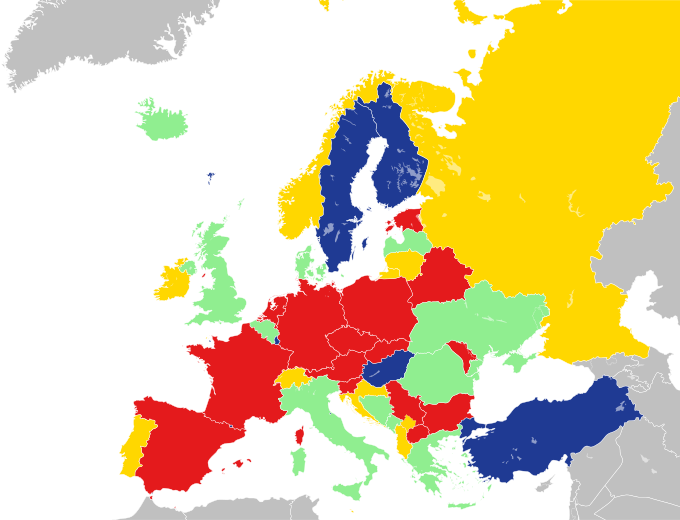

In [5]:
def chromosome_to_svg(chromosome):
    """Return the SVG text of the map coloured according to the chromosome."""
    css_lines = []
    for country, gene in zip(COUNTRIES, chromosome):
        fill = COLORS[gene]
        css_lines.append(f'#{country}, #{country} path {{ fill: {fill}; }}')
    style_block = '<style>' + '\n'.join(css_lines) + '</style>'
    return SVG_TEMPLATE.replace('</svg>', style_block + '</svg>')


def show_map(chromosome):
    """Display the coloured map in the notebook."""
    display(SVG(chromosome_to_svg(chromosome)))


# Test with a random chromosome (this is what a random individual of the first generation looks like)
random_chromosome = [random.randint(0, NUMBER_OF_COLORS - 1) for _ in range(NUMBER_OF_COUNTRIES)]
show_map(random_chromosome)

## 4. Implementation of the Genetic Algorithm

The implementation follows the structure of the course notebook and of Hindi & Yampolskiy (2012):
one small function per step of the GA. All functions work on plain Python lists.

- a **chromosome** is a list of 51 integers (0–3), one per country, in the order of `COUNTRIES`
- a **population** is a list of chromosomes
- the **fitness** of a chromosome is its number of bad edges (lower is better, 0 is a solution)

Every step has a default operator (the one chosen in section 2) and one or more alternatives that
are compared in section 5. The main loop `run_ga` receives the operators as parameters, so that the
same loop is used for every experiment.

### 4.1 Fitness

A *bad edge* is a border where both countries have the same colour. The fitness is the number of bad
edges. `COUNTRY_INDEX` translates a country id into its position in the chromosome.

In [6]:
# position of every country in the chromosome, e.g. COUNTRY_INDEX['fr'] -> 12
COUNTRY_INDEX = {country: index for index, country in enumerate(COUNTRIES)}


def fitness(chromosome):
    """Number of borders where both countries have the same colour (0 = valid colouring)."""
    bad_edges = 0
    for country_a, country_b in BORDERS:
        color_a = chromosome[COUNTRY_INDEX[country_a]]
        color_b = chromosome[COUNTRY_INDEX[country_b]]
        if color_a == color_b:
            bad_edges += 1
    return bad_edges


def conflicting_countries(chromosome):
    """List of the countries that are part of at least one bad edge (used by the mutations)."""
    conflicts = set()
    for country_a, country_b in BORDERS:
        if chromosome[COUNTRY_INDEX[country_a]] == chromosome[COUNTRY_INDEX[country_b]]:
            conflicts.add(country_a)
            conflicts.add(country_b)
    return list(conflicts)


# Quick checks: a map where everything has the same colour has all 89 borders in conflict
all_red = [0] * NUMBER_OF_COUNTRIES
print('all red:', fitness(all_red), 'conflicts')
print('random :', fitness(random_chromosome), 'conflicts')

all red: 89 conflicts
random : 22 conflicts


### 4.2 Initialisation

The first population consists of random chromosomes: every country gets a random colour.

In [7]:
def random_chromosome_():
    return [random.randint(0, NUMBER_OF_COLORS - 1) for _ in range(NUMBER_OF_COUNTRIES)]


def initialise_population(population_size):
    return [random_chromosome_() for _ in range(population_size)]


def evaluate(population):
    """Fitness of every chromosome in the population, in the same order."""
    return [fitness(chromosome) for chromosome in population]

### 4.3 Parent selection

All selection functions have the same signature: they receive the population and its fitness scores
and return **one** parent. The main loop calls them twice to get two parents.

- `tournament_selection` (default): pick `k` random individuals, return the best one. With `k = 2`
  this is the binary tournament of Hindi & Yampolskiy (`parentSelection1`).
- `best_copy_selection`: always return the best individual (`parentSelection2` in the paper).
- `roulette_wheel_selection`: probability proportional to fitness. Because our fitness is minimised,
  it is first turned into a score to maximise: `score = max_fitness - fitness + 1`.
- `rank_selection`: like roulette, but the slice of the wheel depends on the rank (worst = 1,
  best = N), not on the raw fitness.

In [8]:
def tournament_selection(population, fitness_scores, k=2):
    # pick k random positions, keep the one with the lowest fitness
    candidates = random.sample(range(len(population)), k)
    best = candidates[0]
    for index in candidates[1:]:
        if fitness_scores[index] < fitness_scores[best]:
            best = index
    return population[best]


def best_copy_selection(population, fitness_scores):
    best = fitness_scores.index(min(fitness_scores))
    return population[best]


def roulette_wheel_selection(population, fitness_scores):
    # turn "lower is better" into "higher is better" scores; +1 so nobody has score 0
    max_fitness = max(fitness_scores)
    scores = [max_fitness - f + 1 for f in fitness_scores]
    # random.choices picks one element with probability proportional to its weight
    return random.choices(population, weights=scores, k=1)[0]


def rank_selection(population, fitness_scores):
    # sort the positions from worst to best; the weight of an individual is its rank (1 = worst)
    order = sorted(range(len(population)), key=lambda index: fitness_scores[index], reverse=True)
    weights = [0] * len(population)
    for rank, index in enumerate(order, start=1):
        weights[index] = rank
    return random.choices(population, weights=weights, k=1)[0]

### 4.4 Crossover

Both crossover functions receive two parents and return **one** child, as in Hindi & Yampolskiy
(`Algorithm 4`).

- `single_point_crossover` (default): one random cut point; genes before the cut come from parent 1,
  genes after the cut from parent 2.
- `uniform_crossover`: for every gene, a coin flip decides which parent it comes from.

In [9]:
def single_point_crossover(parent1, parent2):
    cut = random.randint(1, NUMBER_OF_COUNTRIES - 1)   # 1..50, so both parts are non-empty
    return parent1[:cut] + parent2[cut:]


def uniform_crossover(parent1, parent2):
    child = []
    for gene1, gene2 in zip(parent1, parent2):
        if random.random() < 0.5:
            child.append(gene1)
        else:
            child.append(gene2)
    return child

### 4.5 Mutation

All mutation functions receive a chromosome and a `mutation_rate` and return a **new** (mutated)
chromosome. The `mutation_rate` is the probability that an individual gene, once selected as a
candidate, is actually changed.

- `random_mutation`: every gene has probability `mutation_rate` of getting a random colour
  (generic mutation, as in the course notebook).
- `conflict_random_mutation` (default): only the countries that are in conflict are candidates;
  each of them gets a random colour with probability `mutation_rate` (`mutation2` in Hindi &
  Yampolskiy, where the rate is 1).
- `conflict_valid_mutation`: same candidates, but the new colour is chosen among the colours that
  none of the neighbours uses; if no such colour exists the country is left unchanged (`mutation1`
  in Hindi & Yampolskiy).

In [10]:
def random_mutation(chromosome, mutation_rate):
    child = list(chromosome)   # copy, so the original is not changed
    for index in range(NUMBER_OF_COUNTRIES):
        if random.random() < mutation_rate:
            child[index] = random.randint(0, NUMBER_OF_COLORS - 1)
    return child


def conflict_random_mutation(chromosome, mutation_rate):
    child = list(chromosome)
    for country in conflicting_countries(chromosome):
        if random.random() < mutation_rate:
            child[COUNTRY_INDEX[country]] = random.randint(0, NUMBER_OF_COLORS - 1)
    return child


def conflict_valid_mutation(chromosome, mutation_rate):
    child = list(chromosome)
    for country in conflicting_countries(chromosome):
        if random.random() < mutation_rate:
            # colours used by the neighbours of this country
            neighbour_colors = set()
            for neighbour in NEIGHBOURS[country]:
                neighbour_colors.add(chromosome[COUNTRY_INDEX[neighbour]])
            valid_colors = [c for c in range(NUMBER_OF_COLORS) if c not in neighbour_colors]
            if len(valid_colors) > 0:
                child[COUNTRY_INDEX[country]] = random.choice(valid_colors)
    return child

### 4.6 Survivor selection

Survivor selection receives the old population, the children (both with their fitness scores) and
returns the new population of `population_size` chromosomes together with its fitness scores.

- `elitism_survival` (default): put parents and children together, sort by fitness, keep the best
  `population_size`.
- `replace_worst_half_survival`: keep the best half of parents + children, fill the other half with
  new random chromosomes (the strategy of Hindi & Yampolskiy).

In [11]:
def elitism_survival(population, fitness_scores, children, children_scores, population_size):
    everyone = population + children
    all_scores = fitness_scores + children_scores
    # sort positions by fitness (lowest first) and keep the best ones
    order = sorted(range(len(everyone)), key=lambda index: all_scores[index])
    survivors = [everyone[index] for index in order[:population_size]]
    survivor_scores = [all_scores[index] for index in order[:population_size]]
    return survivors, survivor_scores


def replace_worst_half_survival(population, fitness_scores, children, children_scores, population_size):
    half = population_size // 2
    # best half of parents + children ...
    survivors, survivor_scores = elitism_survival(population, fitness_scores, children, children_scores, half)
    # ... plus new random chromosomes for the other half
    newcomers = initialise_population(population_size - half)
    return survivors + newcomers, survivor_scores + evaluate(newcomers)

### 4.7 The main loop

`run_ga` puts everything together. It follows the general scheme from section 2 and stops as soon as
a chromosome with fitness 0 is found, or after `max_generations`. It returns a small dictionary with
the result of the run: whether a solution was found, in how many generations, the best chromosome,
and the best fitness of every generation (used for the plots in section 5).

With `animate=True` the map of the best chromosome is redrawn every `animate_every` generations, so
the colouring can be watched while it evolves. A generation only takes a few milliseconds, so
without a pause the frames would go by too fast to see anything: `animate_delay` is the pause in
seconds after every frame (it only slows down the animation, not the algorithm itself).

In [12]:
def run_ga(population_size=50,
           max_generations=500,
           mutation_rate=1.0,
           select_parent=tournament_selection,
           crossover=single_point_crossover,
           mutate=conflict_random_mutation,
           select_survivors=elitism_survival,
           animate=False,
           animate_every=1,
           animate_delay=0.5):

    # INITIALISE and EVALUATE
    population = initialise_population(population_size)
    fitness_scores = evaluate(population)
    best_per_generation = []

    for generation in range(max_generations):
        best_fitness = min(fitness_scores)
        best_chromosome = population[fitness_scores.index(best_fitness)]
        best_per_generation.append(best_fitness)

        if animate and generation % animate_every == 0:
            clear_output(wait=True)
            print(f'generation {generation}: best fitness = {best_fitness} conflicts')
            show_map(best_chromosome)
            time.sleep(animate_delay)   # pause, otherwise the generations go by too fast to see

        # TERMINATION: a valid colouring was found
        if best_fitness == 0:
            break

        # SELECT parents, RECOMBINE and MUTATE to create the children
        children = []
        for _ in range(population_size):
            parent1 = select_parent(population, fitness_scores)
            parent2 = select_parent(population, fitness_scores)
            child = crossover(parent1, parent2)
            child = mutate(child, mutation_rate)
            children.append(child)

        # EVALUATE the children and SELECT the survivors
        children_scores = evaluate(children)
        population, fitness_scores = select_survivors(
            population, fitness_scores, children, children_scores, population_size)

    if animate:
        clear_output(wait=True)
        print(f'generation {generation}: best fitness = {best_fitness} conflicts')
        show_map(best_chromosome)

    return {
        'solved': best_fitness == 0,
        'generations': generation,
        'best_fitness': best_fitness,
        'best_chromosome': best_chromosome,
        'best_per_generation': best_per_generation,
    }

### 4.8 A single run with animation

One run with the default operators. The map is redrawn every generation with a pause of half a
second, until no conflicts are left. Lower `animate_delay` to speed it up.

generation 27: best fitness = 0 conflicts


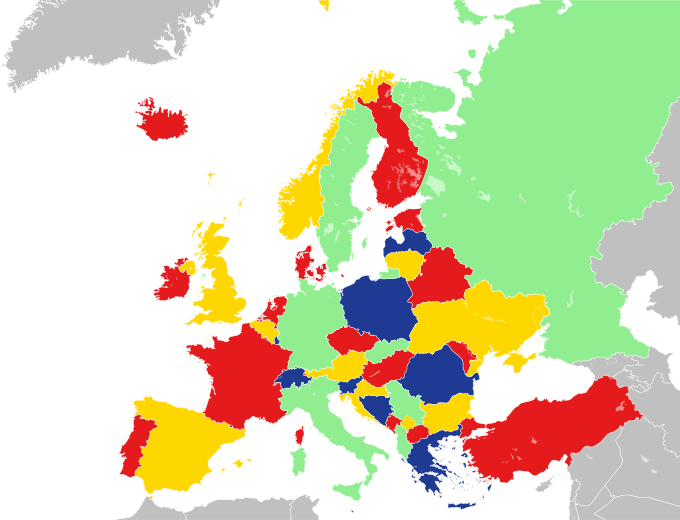

solved: True | generations: 27


In [13]:
result = run_ga(animate=True, animate_every=1, animate_delay=0.1)
print('solved:', result['solved'], '| generations:', result['generations'])

To check the result by hand, the list below shows every border and whether it is in conflict
(it should be empty for a solved run).

In [14]:
best = result['best_chromosome']
conflicts = [(a, b) for a, b in BORDERS if best[COUNTRY_INDEX[a]] == best[COUNTRY_INDEX[b]]]
print('conflicting borders:', conflicts)

conflicting borders: []


## 5. Evaluation

A GA is stochastic, so a single run proves nothing. Every configuration below is run
`NUMBER_OF_RUNS` times, each with a limit of `MAX_GENERATIONS` generations, and compared on:

- **success rate**: fraction of the runs that reached 0 conflicts before the generation limit;
- **average generations**: mean number of generations needed, counted only over the successful runs
  (a failed run stops at the limit, so it would distort the average);
- **average final fitness**: mean number of conflicts left at the end of a run (0 for a solved run);
- **fitness curve**: the best fitness per generation, averaged over all runs of a configuration. Once a
  run is solved, its curve stays at 0.

Every experiment changes **one thing at a time** and keeps the defaults from section 2.7 for the
rest. The random seed is fixed at the start so that the results can be reproduced.

In [15]:
import matplotlib.pyplot as plt

NUMBER_OF_RUNS = 30
MAX_GENERATIONS = 300

random.seed(42)


def run_experiment(name, **ga_parameters):
    """Run the GA NUMBER_OF_RUNS times with the given parameters and collect the statistics."""
    results = [run_ga(max_generations=MAX_GENERATIONS, **ga_parameters) for _ in range(NUMBER_OF_RUNS)]

    solved_runs = [r for r in results if r['solved']]
    success_rate = len(solved_runs) / NUMBER_OF_RUNS
    if len(solved_runs) > 0:
        average_generations = sum(r['generations'] for r in solved_runs) / len(solved_runs)
    else:
        average_generations = None
    average_final_fitness = sum(r['best_fitness'] for r in results) / NUMBER_OF_RUNS

    # average curve: pad every run with 0 (solved) or its last value (not solved) up to MAX_GENERATIONS
    curve = [0] * MAX_GENERATIONS
    for r in results:
        values = r['best_per_generation']
        padded = values + [values[-1]] * (MAX_GENERATIONS - len(values))
        for generation in range(MAX_GENERATIONS):
            curve[generation] += padded[generation] / NUMBER_OF_RUNS

    return {
        'name': name,
        'success_rate': success_rate,
        'average_generations': average_generations,
        'average_final_fitness': average_final_fitness,
        'curve': curve,
    }


def print_table(experiments):
    """Print the statistics of a list of experiments as a text table."""
    print(f'{"configuration":<40} {"success rate":>12} {"avg generations":>16} {"avg final fitness":>18}')
    for e in experiments:
        gens = f'{e["average_generations"]:.1f}' if e['average_generations'] is not None else '-'
        print(f'{e["name"]:<40} {e["success_rate"]:>11.0%} {gens:>16} {e["average_final_fitness"]:>18.2f}')


# one fixed colour per line, in the order the experiments are given
LINE_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']


def plot_curves(experiments, title, last_generation=100):
    """Plot the average best fitness per generation of every experiment."""
    plt.figure(figsize=(8, 4))
    for e, color in zip(experiments, LINE_COLORS):
        plt.plot(range(last_generation), e['curve'][:last_generation], label=e['name'], color=color, linewidth=2)
    plt.title(title)
    plt.xlabel('generation')
    plt.ylabel('best fitness (conflicts), average over runs')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

### 5.1 Parent selection

Tournament (default) against best-copy, roulette wheel and rank selection.

configuration                            success rate  avg generations  avg final fitness
tournament (k=2)                                100%             29.8               0.00
best copy                                        37%             12.5               0.93
roulette wheel                                   97%             30.3               0.03
rank                                             97%             30.4               0.03


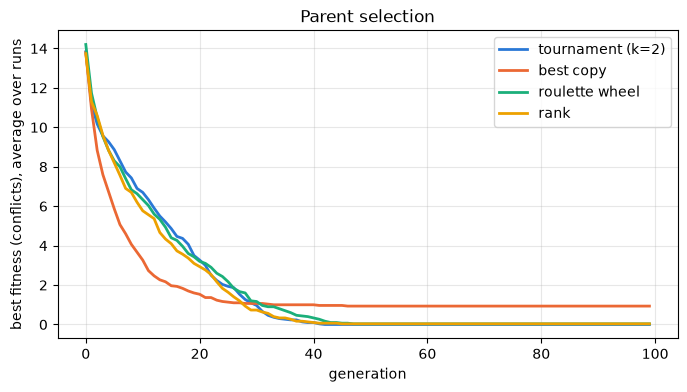

In [16]:
experiment_selection = [
    run_experiment('tournament (k=2)', select_parent=tournament_selection),
    run_experiment('best copy', select_parent=best_copy_selection),
    run_experiment('roulette wheel', select_parent=roulette_wheel_selection),
    run_experiment('rank', select_parent=rank_selection),
]
print_table(experiment_selection)
plot_curves(experiment_selection, 'Parent selection')

**Interpretation.** Tournament, rank and roulette wheel all solve the map in almost every run in
about 30 generations; the differences between them are within the noise of 30 runs. The map is a
small problem, so the stronger exploration of rank selection (which Razali & Geraghty recommend for
large problems) brings no visible advantage here. Best-copy selection is clearly worse: it only
succeeds in a minority of the runs, because both parents are the same chromosome, so crossover does
nothing and the whole population quickly becomes copies of one individual. This matches Hindi &
Yampolskiy, who only use best-copy in the final phase (best fitness <= 4), not from the start.
Tournament selection is kept as the choice: it is the simplest to implement and among the best.

### 5.2 Crossover

Single-point (default) against uniform crossover.

configuration                            success rate  avg generations  avg final fitness
single-point                                     97%             29.6               0.03
uniform                                         100%             63.7               0.00


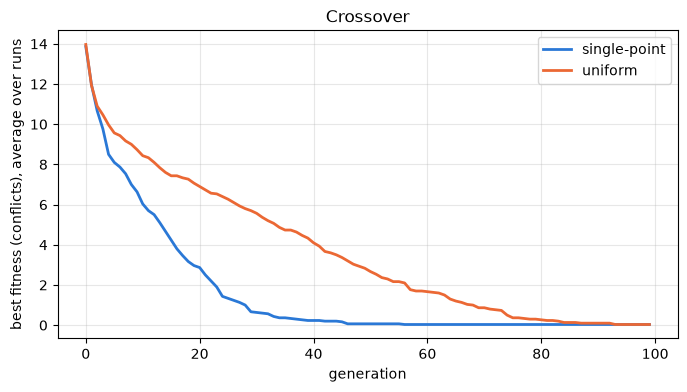

In [17]:
experiment_crossover = [
    run_experiment('single-point', crossover=single_point_crossover),
    run_experiment('uniform', crossover=uniform_crossover),
]
print_table(experiment_crossover)
plot_curves(experiment_crossover, 'Crossover')

**Interpretation.** Both crossovers reach a solution in almost every run, but single-point needs
roughly half the generations of uniform crossover. This is the effect explained in section 2.4: the
countries are ordered by region, so a single cut keeps whole regions (and their borders) intact,
while a uniform coin flip per country breaks up regions that were already consistent in a parent.
Single-point crossover is kept.

### 5.3 Mutation

The two conflict-directed mutations of Hindi & Yampolskiy against the generic random mutation.
The generic mutation is tried with two rates: with rate 1.0 it would change every gene, so it needs
a small rate (a few genes per child on average).

configuration                            success rate  avg generations  avg final fitness
conflict, random colour (rate 1.0)               97%             28.5               0.03
conflict, valid colour (rate 1.0)               100%              6.2               0.00
random gene (rate 0.02)                          37%            115.4               1.00
random gene (rate 0.10)                          67%             99.2               0.33


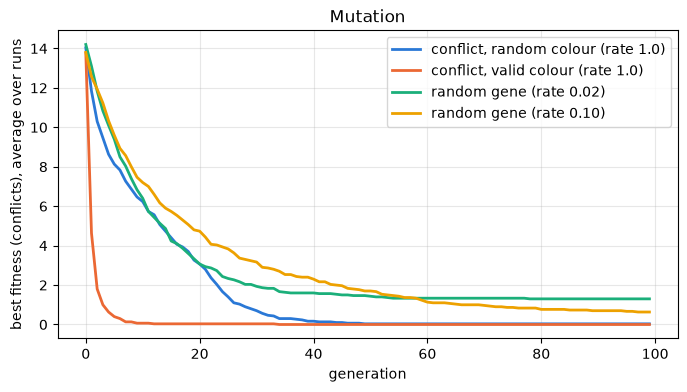

In [18]:
experiment_mutation = [
    run_experiment('conflict, random colour (rate 1.0)', mutate=conflict_random_mutation, mutation_rate=1.0),
    run_experiment('conflict, valid colour (rate 1.0)', mutate=conflict_valid_mutation, mutation_rate=1.0),
    run_experiment('random gene (rate 0.02)', mutate=random_mutation, mutation_rate=0.02),
    run_experiment('random gene (rate 0.10)', mutate=random_mutation, mutation_rate=0.10),
]
print_table(experiment_mutation)
plot_curves(experiment_mutation, 'Mutation')

**Interpretation.** Mutation is the component with the largest effect. The generic random mutation
performs poorly: with a small rate it rarely touches the few countries that are actually wrong, with
a larger rate it also damages the countries that were already correct, and in both cases many runs
do not reach a solution within the limit. Both conflict-directed mutations succeed in (almost) every
run. The "valid colour" variant (`mutation1` of Hindi & Yampolskiy) is by far the fastest, around 7
generations, because it repairs a conflict directly instead of hoping that a random colour is a good
one. The paper warns that this greedy repair can get stuck: when every colour is already used by a
neighbour, the country is left unchanged and only crossover can still help. On this small map that
happens rarely (see also the occasional failed run in section 5.6), so the speed gain clearly wins. The conflict-directed valid-colour mutation is therefore selected as the
best option.

### 5.4 Survivor selection

Elitism (default) against replacing the worst half with random chromosomes.

configuration                            success rate  avg generations  avg final fitness
elitism                                         100%             30.2               0.00
replace worst half                               97%             40.3               0.03


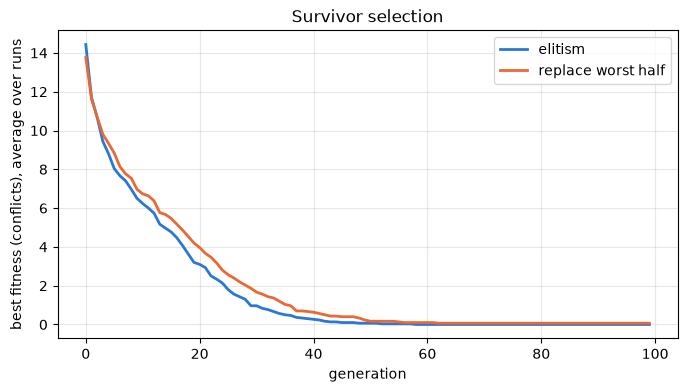

In [19]:
experiment_survival = [
    run_experiment('elitism', select_survivors=elitism_survival),
    run_experiment('replace worst half', select_survivors=replace_worst_half_survival),
]
print_table(experiment_survival)
plot_curves(experiment_survival, 'Survivor selection')

**Interpretation.** Elitism and the replace-worst-half strategy of Hindi & Yampolskiy behave almost
identically on this problem, with elitism slightly faster. Injecting random chromosomes keeps
diversity, but on a small problem that is solved in about 30 generations premature convergence is
not an issue, so the extra random individuals are mostly wasted evaluations. Elitism is kept because
it is simpler.

### 5.5 Hyperparameters

Two hyperparameters are varied with the default operators: the population size (Hindi & Yampolskiy
use 50) and the mutation rate of the conflict-directed mutation (the paper always mutates every
conflicting vertex, i.e. rate 1.0).

configuration                            success rate  avg generations  avg final fitness
population 10                                    70%             55.4               0.30
population 20                                    83%             40.0               0.17
population 50                                    97%             29.4               0.03
population 100                                  100%             25.2               0.00


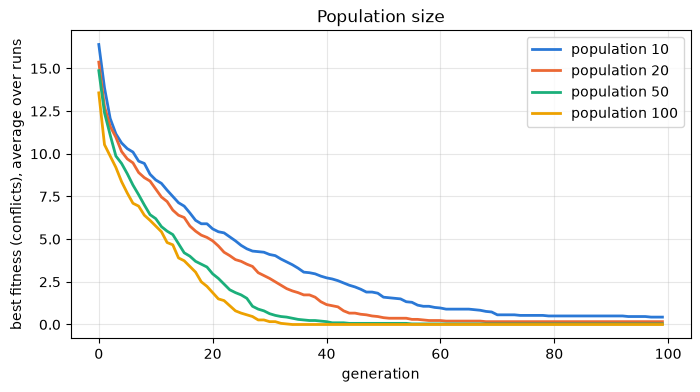

In [20]:
experiment_population = [
    run_experiment('population 10', population_size=10),
    run_experiment('population 20', population_size=20),
    run_experiment('population 50', population_size=50),
    run_experiment('population 100', population_size=100),
]
print_table(experiment_population)
plot_curves(experiment_population, 'Population size')

configuration                            success rate  avg generations  avg final fitness
mutation rate 0.25                               93%             22.0               0.07
mutation rate 0.50                               97%             15.1               0.03
mutation rate 1.00                              100%             28.7               0.00


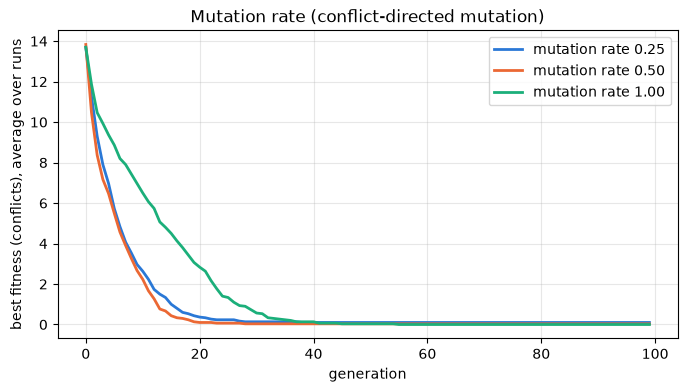

In [21]:
experiment_rate = [
    run_experiment('mutation rate 0.25', mutation_rate=0.25),
    run_experiment('mutation rate 0.50', mutation_rate=0.50),
    run_experiment('mutation rate 1.00', mutation_rate=1.00),
]
print_table(experiment_rate)
plot_curves(experiment_rate, 'Mutation rate (conflict-directed mutation)')

**Interpretation.** A larger population helps: with 10 or 20 chromosomes a noticeable share of the runs
fails, with 50 every run succeeds and with 100 the solution is found in a few generations less. But
every generation of a population of 100 costs twice as many fitness evaluations as one of 50, so 50
is the better trade-off, which agrees with the choice of Hindi & Yampolskiy.

For the mutation rate, a lower rate (0.25 or 0.5) makes the successful runs faster, because fewer
countries are changed at once and a good partial solution is less disturbed, but it also makes more
runs fail: with too little mutation the population converges before every conflict is repaired.
Rate 1.0 (mutate every conflicting country, as in the paper) is the only setting with 100% success
and is kept.

### 5.6 Best combination

The best option of every experiment above, combined into one configuration and compared with the
default configuration of section 2.7. The only difference between the two is the mutation operator.

**Interpretation.** The best combination differs from the default only in the mutation operator,
and that single change reduces the number of generations from about 30 to about 5. The success rate
is the same. Both curves start at the same point (about 14 conflicts for the best random chromosome
of the first generation), but with the valid-colour mutation almost every conflict is repaired in
the first two or three generations.

configuration                            success rate  avg generations  avg final fitness
default (section 2.7)                            97%             28.1               0.03
best combination                                100%              5.9               0.00


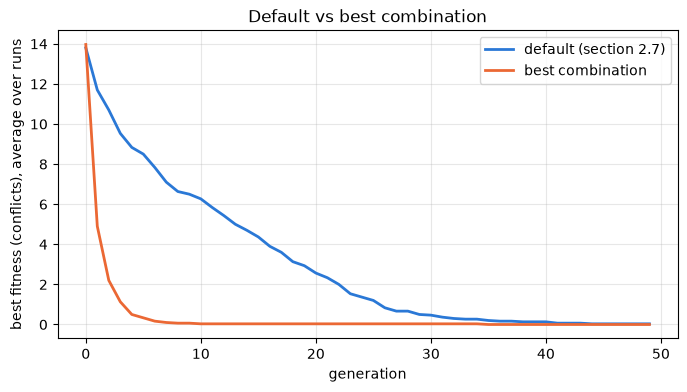

In [22]:
experiment_final = [
    run_experiment('default (section 2.7)'),
    run_experiment('best combination',
                   select_parent=tournament_selection,      # winner of 5.1 (tie, simplest)
                   crossover=single_point_crossover,        # winner of 5.2
                   mutate=conflict_valid_mutation,          # winner of 5.3
                   select_survivors=elitism_survival,       # winner of 5.4 (tie, simplest)
                   population_size=50,                      # 5.5: best trade-off
                   mutation_rate=1.0),                      # 5.5: only rate with 100% success
]
print_table(experiment_final)
plot_curves(experiment_final, 'Default vs best combination', last_generation=50)

### 5.7 The best combination in action

One animated run with the best combination. Because it solves the map in a handful of generations,
the pause between frames is longer than in section 4.8.

generation 7: best fitness = 0 conflicts


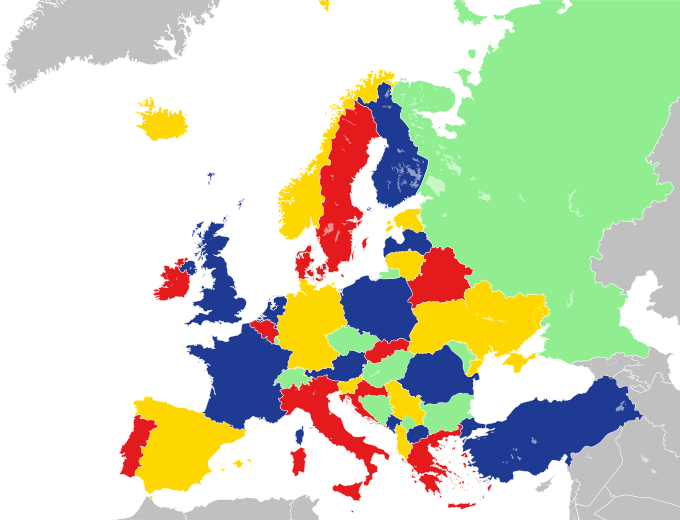

solved: True | generations: 7


In [23]:
result_best = run_ga(select_parent=tournament_selection,
                     crossover=single_point_crossover,
                     mutate=conflict_valid_mutation,
                     select_survivors=elitism_survival,
                     population_size=50,
                     mutation_rate=1.0,
                     animate=True, animate_every=1, animate_delay=1.5)
print('solved:', result_best['solved'], '| generations:', result_best['generations'])

## 6. Conclusion

The goal of this assignment was to colour the map of Europe with four colours using a genetic
algorithm, so that no two bordering countries share a colour. The problem was treated as a graph
colouring problem, following Hindi & Yampolskiy (2012): a chromosome is a list with one colour
number per country, and the fitness is the number of borders in conflict, to be minimised to zero.

For every step of the GA the default operator from the literature was implemented together with at
least one alternative, and all of them were compared on 30 runs each. The results lead to the
following best combination:

| Component | Best choice | Why |
|---|---|---|
| Parent selection | Binary tournament | Tied with rank and roulette wheel on this small problem; simplest of the three. Best-copy selection alone loses diversity and fails most runs. |
| Crossover | Single-point | About twice as fast as uniform crossover, because the countries are ordered by region and a single cut keeps regions intact. |
| Mutation | Conflict-directed, valid colour | The decisive component: it repairs conflicts directly and solves the map in about 5 generations instead of 30. Generic random mutation often fails within the limit. |
| Survivor selection | Elitism | Same results as replacing the worst half with random chromosomes; simpler. |
| Population size | 50 | Smaller populations fail in part of the runs; 100 is only marginally faster at twice the cost per generation. Agrees with Hindi & Yampolskiy. |
| Mutation rate | 1.0 | Lower rates are faster when they succeed but fail more often; mutating every conflicting country is the only setting with (almost) 100% success. |

With this combination the algorithm finds a valid colouring in nearly every run within a handful of
generations, starting from about 14 conflicts in the best random chromosome.

Two observations go beyond the numbers. First, **problem knowledge in the mutation operator matters
far more than the choice of selection or survival scheme**: all the "generic" components gave
similar results, while the mutation that knows about borders changed the outcome by an order of
magnitude. Second, the map of Europe is a small and easy instance: the conclusions of Razali &
Geraghty (2011) about rank selection being better for large problems, and the warning of Hindi &
Yampolskiy that the greedy valid-colour mutation can get stuck, could not really be tested here. The
single failed run of the best combination hints at the second point. On a larger or denser graph the
ranking of the operators could look different, and the switch between the two mutations that the
paper proposes would become relevant.

## References

- Hindi, M. M., & Yampolskiy, R. V. (2012). *Genetic Algorithm Applied to the Graph Coloring Problem.*
  Proceedings of the 23rd Midwest Artificial Intelligence and Cognitive Science Conference (MAICS 2012),
  CEUR Workshop Proceedings Vol. 841. https://ceur-ws.org/Vol-841/submission_10.pdf
- Razali, N. M., & Geraghty, J. (2011). *Genetic Algorithm Performance with Different Selection Strategies
  in Solving TSP.* Proceedings of the World Congress on Engineering 2011, Vol. II, London.
  https://www.iaeng.org/publication/WCE2011/WCE2011_pp1134-1139.pdf
- ZM002 Artificial Intelligence course material, discussion group notebook `ai_dc3_genetic_algorithm.ipynb`,
  Zuyd University of Applied Sciences.
- Map: *Blank map of Europe (with disputed regions).svg*, Wikimedia Commons, public domain.